In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
pd.set_option('display.max_columns', None)
import networkx as nx
import matplotlib.pyplot as plt
from pathlib import Path
from scripts.computations import compute_complexity, compute_assembly, compute_depth
from itertools import islice
import logging
import country_converter as coco
import plotly.express as px
import re
from matplotlib.ticker import FuncFormatter

# actual

In [2]:
# spatial coverage map (reusable for other museum datasets)

logging.getLogger('country_converter').setLevel(logging.ERROR)  # it logs every name it can't match
# country_converter 1.3.2 misreads its own country table under pandas 3, so load the table here and pass it in
_cc_data = pd.read_csv(coco.country_converter.COUNTRY_DATA_FILE, sep='\t', keep_default_na=False, na_values=[''])
cc = coco.CountryConverter(country_data=_cc_data[_cc_data.obsolete.isna()])


def to_iso3(places, sep=',', aliases=None, levels=2):
    '''place strings -> ISO3 code of the first hierarchy level (of the first `levels`) that names a country'''
    parts = places.str.split(sep).str[:levels].apply(lambda lv: [p.strip() for p in lv])
    names = pd.Series(parts.explode().dropna().unique())
    iso = cc.pandas_convert(names, to='ISO3', not_found='NOTFOUND').set_axis(names.values)
    iso = iso.where(iso.astype(str).str.fullmatch(r'[A-Z]{3}'))
    for pattern, code in (aliases or {}).items():  # aliases win over the converter
        iso[names.str.contains(pattern, case=False, regex=True).values] = code
    return parts.apply(lambda lv: next((iso[p] for p in lv if pd.notna(iso[p])), None))


def country_map(df, place_col, base_df=None, sep=',', aliases=None, levels=2, min_n=30, title='', out_dir=None,
                show=True):
    '''Choropleth of where df's rows come from, by country.

    df        : the filtered rows (e.g. objects with a date, place, material and technique)
    place_col : place column; a hierarchy like "Iran,Susa" is read left to right, up to `levels` deep
    base_df   : optional, the whole collection df was filtered from (keep the original index).
                Adds a second map: each country's share of df / its share of base_df.
    aliases   : {regex: ISO3} for names the converter misses or gets wrong, e.g. {'alaska|arizona': 'USA'}
    min_n     : in the ratio map, countries with fewer than min_n rows in base_df are left gray
    out_dir   : folder to save the maps in (interactive html); None = only show them
    show      : False = don't draw the maps in the notebook (with out_dir, they are only saved)
    Returns the per-country table.
    '''
    pop = df if base_df is None else base_df
    iso = to_iso3(pop[place_col].dropna(), sep, aliases, levels)
    unmatched = pop.loc[iso.index[iso.isna()], place_col].str.split(sep).str[0].value_counts()
    print(f'{iso.notna().mean():.1%} of rows with a place were matched to a country. '
          f'Most common unmatched (add to aliases if they belong to one country):')
    print(unmatched.head(15).to_dict())

    tab = pd.DataFrame({'n': iso.reindex(df.index).value_counts()})
    if base_df is not None:
        tab = tab.join(iso.value_counts().rename('n_base'), how='outer').fillna({'n': 0})
    tab.index.name = 'iso3'
    tab['country'] = cc.pandas_convert(tab.index.to_series(), src='ISO3', to='name_short')
    tab['pct'] = tab.n / tab.n.sum() * 100

    geo = dict(showframe=False, showcoastlines=False, showland=True, landcolor='#c3c2b7', bgcolor='#fcfcfb',
               projection_type='natural earth', projection_rotation_lon=0, lataxis_range=[-58, 85])
    layout = dict(margin=dict(l=0, r=0, t=70, b=0), paper_bgcolor='#fcfcfb', font_color='#52514e',
                  title_font_color='#0b0b0b', height=500)
    labels = {'n': 'filtered objects', 'pct': '% of filtered', 'n_base': 'collection objects',
              'pct_base': '% of collection', 'ratio': 'ratio'}
    stem = re.sub(r'\W+', '_', title).strip('_').lower() or 'coverage'

    def finish(fig, name):
        fig.update_traces(marker_line_color='#fcfcfb', marker_line_width=.5)
        fig.update_geos(**geo).update_layout(**layout)
        if out_dir:
            Path(out_dir).mkdir(parents=True, exist_ok=True)
            fig.write_html(Path(out_dir) / f'{stem}_{name}.html')
        if show:
            fig.show()

    # map 1: counts, log color scale
    tab['log_n'] = np.log10(tab.n.where(tab.n > 0))
    ticks = [10 ** k for k in range(int(np.nanmax(tab.log_n)) + 1)]
    fig = px.choropleth(tab, locations=tab.index, color='log_n', hover_name='country', labels=labels,
                        hover_data={'log_n': False, 'n': ':,', 'pct': ':.2f'},
                        color_continuous_scale=['#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95', '#0d366b'],
                        title=f'{title} objects per country<br><sup>n = {int(tab.n.sum()):,} · gray = none</sup>')
    fig.update_coloraxes(colorbar=dict(title='objects', tickvals=np.log10(ticks), ticktext=[f'{t:,}' for t in ticks]))
    finish(fig, 'map_counts')

    # map 2: representation relative to the whole collection, log2 color scale, gray midpoint = 1x
    if base_df is not None:
        tab['pct_base'] = tab.n_base / tab.n_base.sum() * 100
        tab['ratio'] = tab.pct / tab.pct_base
        tab['log2_ratio'] = np.log2(tab.ratio.where(tab.n_base >= min_n).clip(1 / 8, 8))  # 0 objects kept -> 1/8x
        fig = px.choropleth(tab, locations=tab.index, color='log2_ratio', hover_name='country', labels=labels,
                            hover_data={'log2_ratio': False, 'n': ':,', 'n_base': ':,', 'pct': ':.2f',
                                        'pct_base': ':.2f', 'ratio': ':.2f'},
                            color_continuous_scale=['#a82e2e', '#e34948', '#f2a6a2', '#f0efec', '#9ec5f4', '#2a78d6', '#184f95'],
                            range_color=[-3, 3],
                            title=f'{title} representation vs. the whole collection<br><sup>share of filtered rows ÷ share '
                                  f'of collection · red = under-, blue = over-represented · gray = fewer than {min_n} '
                                  f'objects in the collection</sup>')
        fig.update_coloraxes(colorbar=dict(title='ratio', tickvals=list(range(-3, 4)),
                                           ticktext=['≤⅛×', '¼×', '½×', '1×', '2×', '4×', '≥8×']))
        finish(fig, 'map_ratio')

    return tab.drop(columns=[c for c in ['log_n', 'log2_ratio'] if c in tab]).sort_values('n', ascending=False)

In [3]:
# temporal coverage plot (reusable for other museum datasets)

def time_dist(df, early_col, late_col=None, base_df=None, text_col=None, out_dir=None, title='', show=True):
    '''When df's objects were made (midpoint of early-late date): full range on a log axis + zoom on 5000 BCE-today.

    early_col, late_col : numeric year columns (negative = BCE); late_col=None uses early_col alone
    base_df  : optional, the whole collection df was filtered from; drawn in gray for comparison
    text_col : optional date text column; rows whose text says BCE (and not CE) get negative years,
               which fixes BCE dates stored with a positive sign
    out_dir  : folder to save the figure in (png); None = only show it
    show     : False = don't draw the figure in the notebook (with out_dir, it is only saved)
    Returns a table of date quantiles.
    '''
    now = pd.Timestamp.now().year

    def midpoints(d, name):
        e = pd.to_numeric(d[early_col], errors='coerce')
        l = e if late_col is None else pd.to_numeric(d[late_col], errors='coerce')
        if text_col:
            t = d[text_col].fillna('').astype(str)
            bce = t.str.contains(r'B\.?C') & ~t.str.contains(r'(?<!B)C\.?E\b|\bA\.?D\b')
            fixed = bce & ((e > 0) | (l > 0))
            e, l = e.where(~bce, -e.abs()), l.where(~bce, -l.abs())
            print(f'{name}: {fixed.sum():,} BCE dates stored with a positive sign were corrected')
        mid = ((e + l) / 2).dropna()
        print(f'{name}: {len(mid):,} rows with a numeric date, {(mid > now).sum():,} dated after {now} dropped')
        return mid[mid <= now]

    groups = {} if base_df is None else {'collection': midpoints(base_df, 'collection')}
    groups['filtered'] = midpoints(df, 'filtered')
    styles = {'collection': dict(color='#c3c2b7'), 'filtered': dict(histtype='step', color='#2a78d6', lw=2)}
    q = [0, .05, .25, .5, .75, .95, 1]
    summary = pd.DataFrame({k: m.quantile(q) for k, m in groups.items()}).round(0)

    fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 7), facecolor='#fcfcfb', gridspec_kw={'hspace': .5})
    oldest = now - min(m.min() for m in groups.values())
    log_bins = np.logspace(0, np.log10(max(oldest, 10)) + .05, 70)
    for k, m in groups.items():
        top.hist((now - m).clip(lower=1), log_bins, weights=np.full(len(m), 100 / len(m)),
                 label=f'{k} (n = {len(m):,})', **styles[k])
        z = m[m >= -5000]
        bottom.hist(z, np.arange(-5000, now + 100, 100), weights=np.full(len(z), 100 / max(len(z), 1)),
                    label=f'{k}: {len(z) / len(m):.0%} of its dates fall in this window', **styles[k])
    top.set_xscale('log')
    top.invert_xaxis()  # oldest on the left
    top.xaxis.set_major_formatter(FuncFormatter(
        lambda v, _: f'{v / 1e6:g}M' if v >= 1e6 else f'{v / 1e3:g}k' if v >= 1e4 else f'{v:,.0f}'))
    top.set_title(f'full range: years before {now} (log scale)', loc='left', fontsize=11)
    bottom.xaxis.set_major_formatter(FuncFormatter(
        lambda v, _: f'{-v:.0f} BCE' if v < 0 else f'{v:.0f} CE' if v > 0 else '0'))
    bottom.set_xticks(np.arange(-5000, now, 1000))
    bottom.set_xlim(-5000, now + 100)
    bottom.set_title('zoom: 5000 BCE to today, 100-year bins', loc='left', fontsize=11)
    for ax in (top, bottom):
        ax.set_facecolor('#fcfcfb')
        ax.set_ylabel('% of objects in each bin', color='#52514e')
        ax.grid(axis='y', color='#e1e0d9', lw=.6)
        ax.set_axisbelow(True)
        ax.tick_params(length=0, colors='#898781')
        for s in ('top', 'right', 'left'):
            ax.spines[s].set_visible(False)
        ax.spines['bottom'].set_color('#c3c2b7')
        ax.legend(frameon=False, loc='upper left', fontsize=9)
    fig.suptitle(f'{title} when objects were made (midpoint of early–late date)', x=.125, ha='left', fontsize=13)

    if out_dir:
        Path(out_dir).mkdir(parents=True, exist_ok=True)
        stem = re.sub(r'\W+', '_', title).strip('_').lower() or 'coverage'
        fig.savefig(Path(out_dir) / f'{stem}_time.png', dpi=150, bbox_inches='tight', facecolor='#fcfcfb')
    if show:
        plt.show()
    else:
        plt.close(fig)  # without this the notebook still draws the figure when the cell finishes
    return summary

### Penn

In [11]:
penn_df = pd.read_csv('data/real/museums/penn.csv')
from scripts.scrapers.technology_filter import is_technology
penn_df = penn_df[[is_technology(t, m, q) for t, m, q in zip(penn_df.objectName, penn_df.material, penn_df.technique)]]

C:\Users\User\AppData\Local\Temp\ipykernel_4884\2427743519.py:1: DtypeWarning: Columns (3: onDisplay, 19: iconographySubject, 22: earlyDate, 23: lateDate) have mixed types. Specify dtype option on import or set low_memory=False.
  penn_df = pd.read_csv('data/real/museums/penn.csv')


In [12]:
# Penn: objects with date + place + material + technique vs the whole collection
FIG_DIR = 'figures/penn'  # where the coverage figures are saved; None = don't save
SHOW_FIGS = True         # True = also draw the figures in the notebook
penn_filtered = penn_df[penn_df[['dateMade', 'placeName', 'material', 'technique']].notna().all(axis=1)]
penn_aliases = {  # names the converter misses; broad regions (Mediterranean, Africa, Borneo, ...) are left unmatched
    r'alaska|arizona|new mexico|california|colorado|utah|washington \(u|montana|oregon|ohio|wyoming|nevada|dakota|unites states': 'USA',
    'philippine': 'PHL', 'siberia': 'RUS', 'crimea': 'UKR', r'sumatra|^java|sulawesi|celebes': 'IDN', 'tibet': 'CHN',
    r'caroline islands|truk': 'FSM', 'holland': 'NLD', r'society islands|marquesas': 'PYF', 'johore': 'MYS',
    r'admiralty islands|wuvulu|^aua$': 'PNG', 'gilbert islands': 'KIR', r'beth shemesh|beth shean': 'ISR'}
penn_countries = country_map(penn_filtered, 'placeName', base_df=penn_df, aliases=penn_aliases, title='Penn:',
                             out_dir=FIG_DIR, show=SHOW_FIGS)
penn_countries.head(15)

95.0% of rows with a place were matched to a country. Most common unmatched (add to aliases if they belong to one country):
{'Mediterranean': 9807, 'Borneo': 1893, 'North America': 1278, 'Africa': 1028, 'Great Plains (Plain)': 823, 'Near East': 667, 'Europe (uncertain)': 564, 'Asia': 459, 'Europe': 458, 'South America': 264, 'West Indies': 133, 'North Africa': 120, 'Polynesia': 105, 'South Arabia': 104, 'Arabian Peninsula': 101}


,n,n_base,country,pct,pct_base,ratio
iso3,,,,,,
EGY,2190.0,46017,Egypt,14.827353,11.674316,1.270083
ITA,1647.0,7602,Italy,11.150982,1.928595,5.781920
JOR,1618.0,10189,Jordan,10.954638,2.584906,4.237926
CHN,1489.0,7639,China,10.081246,1.937982,5.201931
JPN,1070.0,4018,Japan,7.244414,1.019349,7.106900
IND,883.0,3666,India,5.978334,0.930048,6.427982
USA,812.0,82026,United States,5.497630,20.809644,0.264187
IRQ,666.0,40051,Iraq,4.509140,10.160767,0.443780
THA,501.0,1722,Thailand,3.392011,0.436864,7.764455


In [6]:
# Penn: when the filtered objects were made vs the whole collection (FIG_DIR and SHOW_FIGS are set in the map cell above)
time_dist(penn_filtered, 'earlyDate', 'lateDate', base_df=penn_df, text_col='dateMade', out_dir=FIG_DIR, title='Penn:',
          show=False)

collection: 1,975 BCE dates stored with a positive sign were corrected
collection: 97,491 rows with a numeric date, 55 dated after 2026 dropped
filtered: 272 BCE dates stored with a positive sign were corrected
filtered: 15,922 rows with a numeric date, 6 dated after 2026 dropped


,collection,filtered
0.00,-943000.0,-105250.0
0.05,-3750.0,-4250.0
0.25,-1750.0,-650.0
0.50,-500.0,300.0
0.75,1600.0,1850.0
0.95,1932.0,1958.0
1.00,2025.0,2025.0


### British Museum

In [8]:
bm_df = pd.read_csv('data/real/bm.csv')
FIG_DIR = 'figures/bm'  # where the coverage figures are saved; None = don't save
SHOW_FIGS = True         # True = also draw the figures in the notebook
bm_filtered = bm_df[bm_df[['dateMade', 'placeName', 'material', 'technique']].notna().all(axis=1)]

In [ ]:
# space
bm_aliases = {  # names the converter misses; broad regions (Mediterranean, Africa, Borneo, ...) are left unmatched
    r'alaska|arizona|new mexico|california|colorado|utah|washington \(u|montana|oregon|ohio|wyoming|nevada|dakota|unites states': 'USA',
    'philippine': 'PHL', 'siberia': 'RUS', 'crimea': 'UKR', r'sumatra|^java|sulawesi|celebes': 'IDN', 'tibet': 'CHN',
    r'caroline islands|truk': 'FSM', 'holland': 'NLD', r'society islands|marquesas': 'PYF', 'johore': 'MYS',
    r'admiralty islands|wuvulu|^aua$': 'PNG', 'gilbert islands': 'KIR', r'beth shemesh|beth shean': 'ISR'}
bm_countries = country_map(bm_filtered, 'placeName', base_df=bm_df, aliases=bm_aliases, title='bm:',
                             out_dir=FIG_DIR, show=SHOW_FIGS)
bm_countries.head(15)

In [9]:
# time
time_dist(bm_filtered, 'earlyDate', 'lateDate', base_df=bm_df, text_col='dateMade', out_dir=FIG_DIR, title='BM:',
          show=False)

KeyError: 'earlyDate'

# toy/test

individual scores

In [ ]:
# setup
la_path = Path('data/toy/little_alchemy_2')
ohol_path = Path('data/toy/one_hour_one_life')

la2_c_df = compute_complexity(la_path / 'recipes_edgelist.csv')
ohol_c_df = compute_complexity(ohol_path / 'recipes_edgelist.csv')

la2_d_df = compute_depth(la_path / 'recipes_default.csv')
ohol_d_df = compute_depth(ohol_path / 'recipes_default.csv')

la2_a_df = compute_assembly(la_path / 'assembly_edgelist.csv')
ohol_a_df = compute_assembly(ohol_path / 'assembly_edgelist.csv')

In [4]:
# sample to check against hand computations
print(la2_a_df.sort_values(by=la2_a_df.columns[1], ascending=True).head(5))

   Fire  Time  Earth  Water  Air  Land  Smoke  Puddle  Dust  Continent  ...  \
0     0     0      0      0    0     1      1       1     1          2  ...   

   Mousetrap  Pizza  Treasure  Bulletproof Vest  Sand Castle  Mouse  \
0         67     63        99                90           91     53   

   Hamburger  Cheeseburger  Grilled Cheese  Bat  
0         71           119              85   54  

[1 rows x 719 columns]


group scores

In [5]:
# test group index

## eval
All three scores are recomputed from each game's recipe table (`result,input_1,input_2`), so the robustness tests can drop recipes or items in memory and rerun the same functions.

In [29]:
from io import StringIO

METRICS = ['complexity', 'depth', 'assembly']
games = {'LA2': la_path, 'OHOL': ohol_path}
recipes = {g: pd.read_csv(p / 'recipes_default.csv') for g, p in games.items()}

def as_files(r):
    '''recipe table -> in-memory versions of the three files the compute functions read'''
    cols = ['input', 'result', 'partner']
    fwd = r[['input_1', 'result', 'input_2']].set_axis(cols, axis=1)
    rev = r[r.input_1 != r.input_2][['input_2', 'result', 'input_1']].set_axis(cols, axis=1)
    asm = pd.concat([fwd, rev])
    buf = lambda df, header=False: StringIO(df.to_csv(index=False, header=header, lineterminator='\n'))
    return buf(asm[['input', 'result']].drop_duplicates()), buf(r[['result', 'input_1', 'input_2']], True), buf(asm)

def scores(r):
    edges, table, asm = as_files(r)
    return pd.DataFrame({'complexity': compute_complexity(edges).set_index('Tech')['Complexity'],
                         'depth': compute_depth(table).iloc[0],
                         'assembly': compute_assembly(asm).iloc[0]})

S = {g: scores(r) for g, r in recipes.items()}

### 1. metrics against each other
Diagonal: each score's distribution. Off-diagonal: pairs of scores. Both on a log10(score + 1) scale. ρ is Spearman (rank) correlation, since the relationships are monotone but not linear.

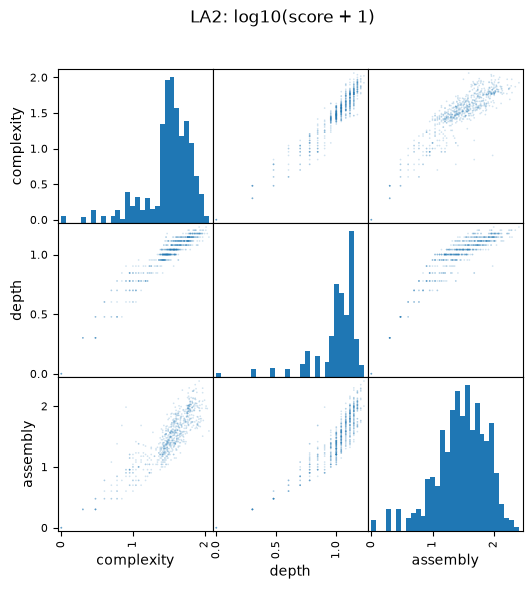

,median,max,skew,ρ complexity,ρ depth,ρ assembly
complexity,35.0,114.0,0.56,1.00,0.91,0.87
depth,10.0,16.0,-0.84,0.91,1.00,0.88
assembly,31.0,257.0,1.70,0.87,0.88,1.00


assembly rank << depth rank: ['Katana', 'Rust', 'Blender'] 
assembly rank >> depth rank: ['Galaxy Cluster', 'City', 'Universe']


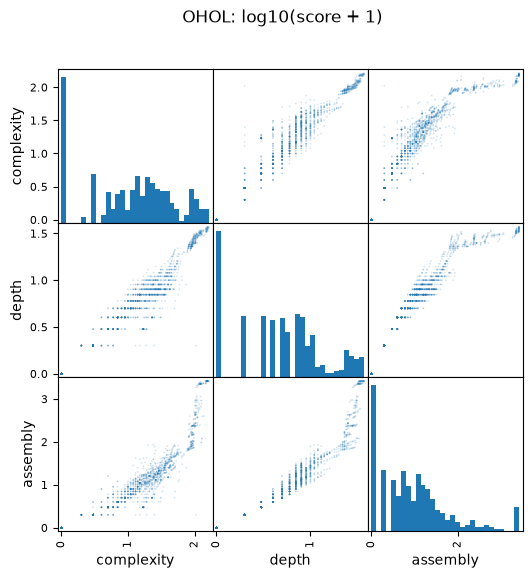

,median,max,skew,ρ complexity,ρ depth,ρ assembly
complexity,12.0,163.0,1.97,1.00,0.96,0.96
depth,4.0,36.0,1.76,0.96,1.00,0.98
assembly,7.0,2607.0,4.83,0.96,0.98,1.00


assembly rank << depth rank: ['Hot Candle', 'Molten Palm Wax', 'Bowl of Palm Wax'] 
assembly rank >> depth rank: ['Green Bowler Hat', 'Northwestward Gradient Dry Spring', 'Northwestward Gradient Dry Tarry Spot']


In [7]:
for g, s in S.items():
    pd.plotting.scatter_matrix(np.log10(s + 1), figsize=(6, 6), alpha=.2, s=6, hist_kwds={'bins': 30})
    plt.suptitle(f'{g}: log10(score + 1)')
    plt.show()
    display(pd.concat([s.agg(['median', 'max', 'skew']).T, s.corr('spearman').add_prefix('ρ ')], axis=1).round(2))
    # where the two pathway-based scores disagree most (rank percentile gap, craftable items)
    gap = s[s.depth > 0].rank(pct=True).pipe(lambda k: k.assembly - k.depth).sort_values()
    print('assembly rank << depth rank:', list(gap.index[:3]), '\nassembly rank >> depth rank:', list(gap.index[-3:]))

### 2. validity (OHOL only)
LA2's data has no independent complexity measure (only name, letter and recipe count), so this section is OHOL only.

**What we know here that we won't for real technologies**
- The complete recipe set, so a missing recipe is a choice we made by filtering, not an unknown.
- The true starting items (`natural` means the item spawns on the map).
- `game_depth`: the game engine's own depth, computed over *every* transition, including the steps the tech tree filtered out.
- Development order (object IDs are assigned in creation order). The real-world analogue, invention or patent dates, is partly knowable, so this is the more realistic check.

**Basal problem.** 347 of OHOL's 413 starting items aren't natural. They're starting items only because their production steps were filtered out, and their `game_depth` averages 44. Every score counts up from those items, while `game_depth` counts up from natural items. To put both on the same baseline, `game_depth` is re-based by subtracting the `game_depth` of the highest starting item the item is built on. Starting items themselves are left out, since every score is 0 for them by definition.

,game_depth,game_depth_rebased,dev_order
complexity,0.55,0.69,0.26
depth,0.54,0.71,0.22
assembly,0.54,0.73,0.24


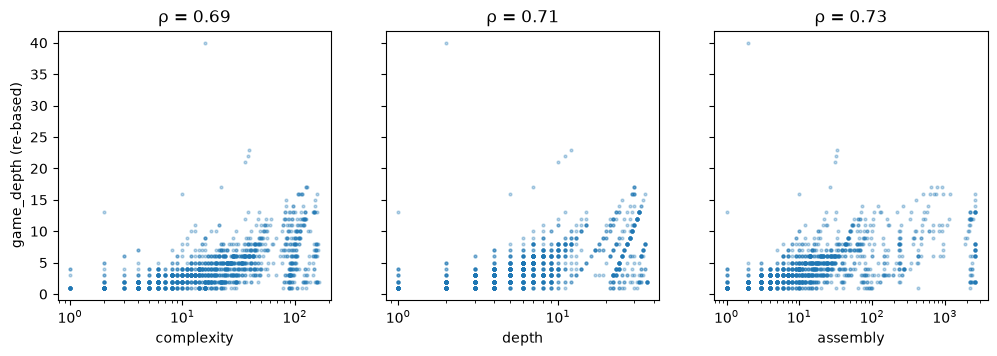

In [8]:
o = pd.read_csv(ohol_path / 'items.csv').set_index('item')
G = nx.read_edgelist(ohol_path / 'recipes_edgelist.csv', delimiter=',', create_using=nx.DiGraph)
starts = set(o.index[o.base == 1])
o['start_depth'] = [max((o.game_depth[b] for b in nx.ancestors(G, n) & starts), default=o.game_depth[n]) for n in o.index]
o['game_depth_rebased'] = o.game_depth - o.start_depth
o['dev_order'] = o.object_ids.astype(str).str.split().apply(lambda ids: min(map(int, ids)))

v = S['OHOL'].join(o)[lambda d: d.base == 0]
display(pd.DataFrame({p: v[METRICS].corrwith(v[p], method='spearman')
                      for p in ['game_depth', 'game_depth_rebased', 'dev_order']}).round(2))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, m in zip(axes, METRICS):
    ax.scatter(v[m], v.game_depth_rebased, s=4, alpha=.3)
    ax.set(xscale='log', xlabel=m, title=f'ρ = {v[m].corr(v.game_depth_rebased, method="spearman"):.2f}')
axes[0].set_ylabel('game_depth (re-based)')
plt.show()

### 3. robustness
Drop a fraction of the recipes or of the craftable items (a dropped item takes every recipe that uses or makes it), recompute, and compare with the full-data scores on the items that are left (Spearman ρ, mean of 10 runs). Starting items are never dropped. The biased runs make deep items (above median depth) 4× as likely to go missing as shallow ones, or the reverse. `new_basals` counts items that lose all inputs.

In [9]:
rng = np.random.default_rng(0)

def drop(r, frac, unit, w=None):
    '''remove frac of the recipes or craftable items, sampled in proportion to item weights w'''
    pool = r.index if unit == 'recipes' else pd.Index(r.result.unique())
    p = None if w is None else w.reindex(r.result if unit == 'recipes' else pool).to_numpy(float)
    gone = rng.choice(pool, int(frac * len(pool)), replace=False, p=None if p is None else p / p.sum())
    return r.drop(gone) if unit == 'recipes' else r[~r[['result', 'input_1', 'input_2']].isin(gone).any(axis=1)]

def robustness(g, fracs=(.05, .1, .2, .3, .5), reps=10):
    r, base = recipes[g], S[g]
    deep = (base.depth > base.depth[base.depth > 0].median()).astype(int)
    scenarios = {'random recipes': ('recipes', None), 'random items': ('items', None),
                 'deep items 4x': ('items', 1 + 3 * deep), 'shallow items 4x': ('items', 4 - 3 * deep)}
    rows = []
    for name, (unit, w) in scenarios.items():
        for f in fracs:
            for _ in range(reps):
                s = scores(drop(r, f, unit, w))
                b = base.loc[s.index]
                rows.append({'scenario': name, 'frac': f, **s.corrwith(b, method='spearman'),
                             'new_basals': ((s.depth == 0) & (b.depth > 0)).sum()})
    return pd.DataFrame(rows)

rob = {g: robustness(g) for g in games}

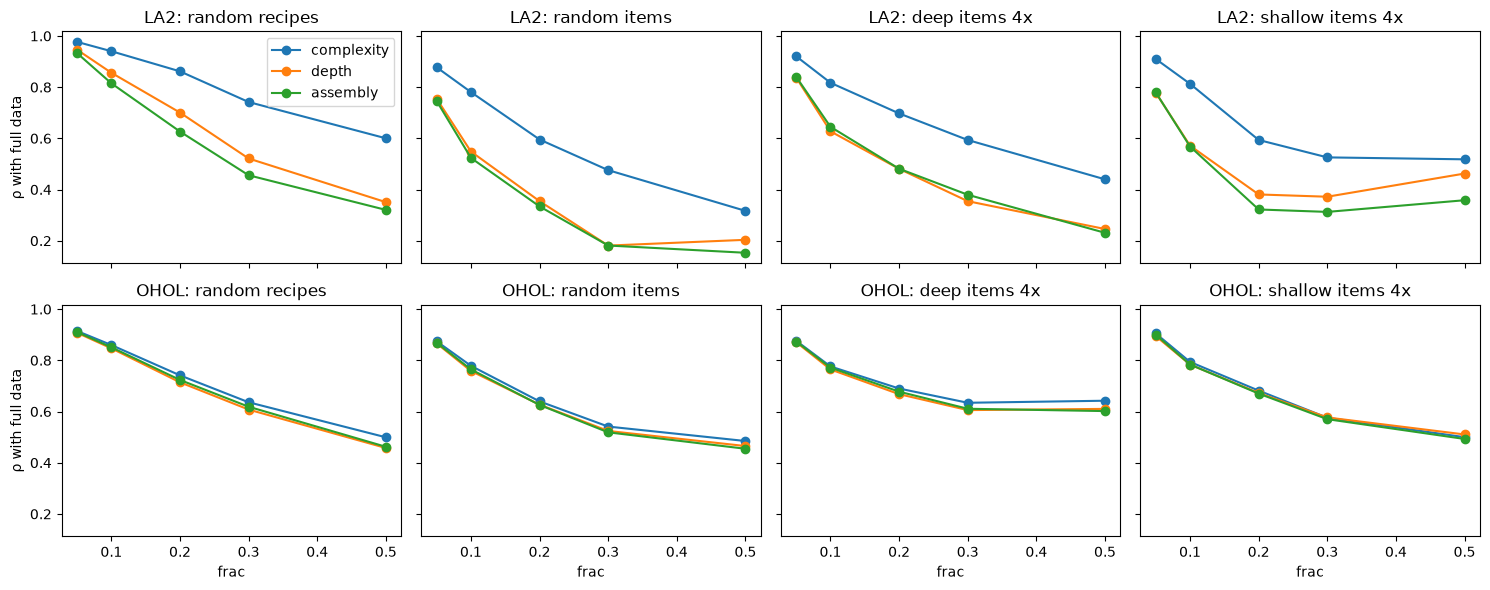

complexity  depth  assembly  new_basals
     scenario                                                 
LA2  random recipes          0.86   0.70      0.63        41.4
     random items            0.60   0.35      0.33        72.2
     deep items 4x           0.70   0.48      0.48        43.2
     shallow items 4x        0.59   0.38      0.32        83.1
OHOL random recipes          0.74   0.71      0.72       164.6
     random items            0.64   0.63      0.63       149.2
     deep items 4x           0.69   0.67      0.68       108.0
     shallow items 4x        0.68   0.67      0.67       165.5

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6), sharex=True, sharey=True)
for row, (g, res) in zip(axes, rob.items()):
    for ax, (name, d) in zip(row, res.groupby('scenario', sort=False)):
        d.groupby('frac')[METRICS].mean().plot(ax=ax, marker='o', legend=False, title=f'{g}: {name}')
    row[0].set_ylabel('ρ with full data')
axes[0, 0].legend()
plt.tight_layout()
plt.show()
# at 20% removed
display(pd.concat({g: res[res.frac == .2].groupby('scenario', sort=False)[METRICS + ['new_basals']].mean()
                   for g, res in rob.items()}).round(2))